<a href="https://colab.research.google.com/github/Yesid-Valencia/IntroduccionML---Especializacion-IA/blob/main/segmentacion_inmuebles_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Implementación de K-Means

Dimensiones del dataset: (2000, 8)
          Tipo  Habitaciones  Baños  Area            Barrio       Valor  \
0         Casa             4      4   280           Usaquen  1200000000   
1  Apartamento             1      1    64   Chico Reservado   495000000   
2  Apartamento             3      2   115  Colina Campestre   518000000   
3  Apartamento             2      2    81          Cedritos   515000000   
4  Apartamento             3      2    60          Engativa   276000000   

                                Descripcion  \
0                  Casa en venta en Usaquen   
1   Apartamento en venta en Chico Reservado   
2  Apartamento en venta en Colina Campestre   
3          Apartamento en venta en Cedritos   
4          Apartamento en venta en Engativa   

                                   UPZ  
0                              Usaquen  
1  CHAPINERO: ChicÃ³ Lago + El Refugio  
2                                 Niza  
3                              Usaquen  
4                         

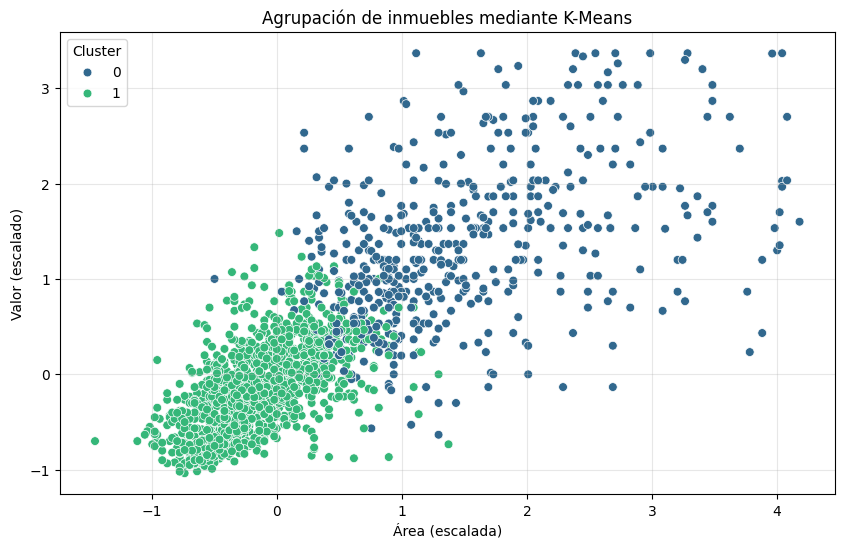


Características promedio por cluster:
                Habitaciones  Baños    Area         Valor
Cluster_KMeans                                           
0                       3.06   3.10  149.00  7.846274e+08
1                       2.46   1.81   66.69  3.275104e+08

Archivo de resultados generado correctamente.


In [2]:

# ============================================
# PROYECTO: CLUSTERING INMOBILIARIO BOGOTÁ
# ALGORITMO 1: K-MEANS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. CARGAR DATASET ORIGINAL
df = pd.read_csv('/content/Inmuebles_Bogota_2000_limpios.csv')

print("Dimensiones del dataset:", df.shape)
print(df.head())

# 2. SELECCIONAR VARIABLES
variables = ['Tipo', 'Habitaciones', 'Baños', 'Area', 'Valor']

datos = df[variables].copy()

# 3. CODIFICAR VARIABLE CATEGÓRICA
# Apartamento = 0
# Casa = 1

datos['Tipo'] = datos['Tipo'].map({
    'Apartamento': 0,
    'Casa': 1
})

# 4. IDENTIFICAR VARIABLES NUMÉRICAS
variables_numericas = [
    'Habitaciones',
    'Baños',
    'Area',
    'Valor'
]

# 5. APLICAR ROBUST SCALER
scaler = RobustScaler()

datos_escalados = scaler.fit_transform(
    datos[variables_numericas]
)

# Convertir nuevamente a DataFrame
X = pd.DataFrame(
    datos_escalados,
    columns=variables_numericas,
    index=datos.index
)

# Incorporar variable Tipo codificada
X['Tipo'] = datos['Tipo']

# 6. VERIFICAR RESULTADOS DEL ESCALAMIENTO
print("\nDatos originales:")
print(datos.head())

print("\nDatos escalados:")
print(X.head())

print("\nMedianas utilizadas:")
print(scaler.center_)

print("\nEscalas IQR utilizadas:")
print(scaler.scale_)

# 7. ENTRENAR K-MEANS
kmeans = KMeans(
    n_clusters=2,
    init='k-means++',
    n_init=20,
    random_state=42
)

labels_kmeans = kmeans.fit_predict(X)

# 8. AGREGAR RESULTADOS
df['Cluster_KMeans'] = labels_kmeans

print("\nCantidad de inmuebles por cluster:")
print(df['Cluster_KMeans'].value_counts())

# 9. EVALUAR MODELO
silhouette = silhouette_score(X, labels_kmeans)

print("\nSilhouette Score:", round(silhouette, 4))

# 10. VISUALIZAR RESULTADOS
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X['Area'],
    y=X['Valor'],
    hue=labels_kmeans,
    palette='viridis',
    s=40
)

plt.title('Agrupación de inmuebles mediante K-Means')
plt.xlabel('Área (escalada)')
plt.ylabel('Valor (escalado)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

# 11. PERFIL DE LOS GRUPOS
df['Cluster_KMeans'] = labels_kmeans

print("\nCaracterísticas promedio por cluster:")
print(
    df.groupby('Cluster_KMeans')[
        ['Habitaciones', 'Baños', 'Area', 'Valor']
    ].mean().round(2)
)

# 12. EXPORTAR RESULTADOS
df.to_csv(
    '/content/Resultados_KMeans.csv',
    index=False
)

print("\nArchivo de resultados generado correctamente.")


### Implementación de DBSCAN

Dimensiones del dataset: (2000, 8)

Primeros registros escalados:
   Habitaciones  Baños      Area     Valor  Tipo
0           1.0    2.0  4.079602  2.700000     1
1          -2.0   -1.0 -0.218905  0.350000     0
2           0.0    0.0  0.796020  0.426667     0
3          -1.0    0.0  0.119403  0.416667     0
4           0.0    0.0 -0.298507 -0.380000     0

Medianas utilizadas:
[3.0e+00 2.0e+00 7.5e+01 3.9e+08]

Escalas IQR utilizadas:
[1.000e+00 1.000e+00 5.025e+01 3.000e+08]

Cantidad de registros por grupo:
Cluster_DBSCAN
-1    414
 0     89
 1    559
 2    249
 3    138
 4    103
 5     72
 6    223
 7    119
 8     34
Name: count, dtype: int64

Registros identificados como ruido: 414
Porcentaje de ruido: 20.7 %

Silhouette Score: 0.4592


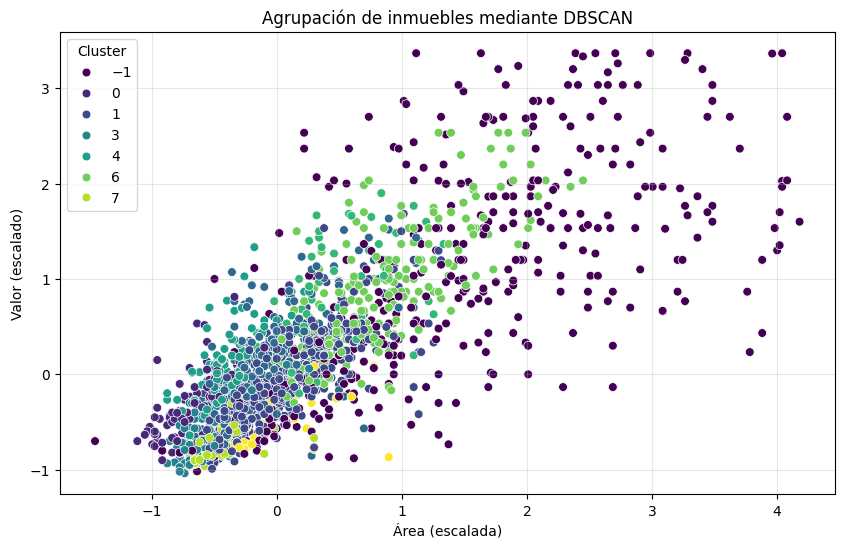


Características promedio por cluster:
                Habitaciones  Baños    Area         Valor
Cluster_DBSCAN                                           
0                        1.0    1.0   42.13  3.052547e+08
1                        3.0    2.0   75.82  3.554873e+08
2                        2.0    2.0   71.82  4.203628e+08
3                        2.0    1.0   46.54  1.798479e+08
4                        1.0    2.0   55.10  4.192261e+08
5                        2.0    3.0   94.46  6.014235e+08
6                        3.0    3.0  115.30  6.373641e+08
7                        3.0    1.0   50.33  1.621054e+08
8                        3.0    2.0   77.32  2.545085e+08

Archivo de resultados generado correctamente.


In [17]:

# ============================================
# PROYECTO: CLUSTERING INMOBILIARIO BOGOTÁ
# ALGORITMO 2: DBSCAN
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# 1. CARGAR DATASET ORIGINAL
df = pd.read_csv('/content/Inmuebles_Bogota_2000_limpios.csv')

print("Dimensiones del dataset:", df.shape)

# 2. SELECCIONAR VARIABLES
variables = ['Tipo', 'Habitaciones', 'Baños', 'Area', 'Valor']

datos = df[variables].copy()

# 3. CODIFICAR VARIABLE CATEGÓRICA
# Apartamento = 0
# Casa = 1

datos['Tipo'] = datos['Tipo'].map({
    'Apartamento': 0,
    'Casa': 1
})

# 4. IDENTIFICAR VARIABLES NUMÉRICAS
variables_numericas = [
    'Habitaciones',
    'Baños',
    'Area',
    'Valor'
]

# 5. APLICAR ROBUST SCALER
scaler = RobustScaler()

datos_escalados = scaler.fit_transform(
    datos[variables_numericas]
)

X = pd.DataFrame(
    datos_escalados,
    columns=variables_numericas,
    index=datos.index
)

# Incorporar variable Tipo codificada
X['Tipo'] = datos['Tipo']

# 6. VERIFICAR ESCALAMIENTO
print("\nPrimeros registros escalados:")
print(X.head())

print("\nMedianas utilizadas:")
print(scaler.center_)

print("\nEscalas IQR utilizadas:")
print(scaler.scale_)

# 7. ENTRENAR DBSCAN
dbscan = DBSCAN(
    eps=0.65,
    min_samples=25,
    metric='euclidean'
)

labels_dbscan = dbscan.fit_predict(X)

# 8. AGREGAR RESULTADOS
df['Cluster_DBSCAN'] = labels_dbscan

print("\nCantidad de registros por grupo:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

# 9. IDENTIFICAR RUIDO
ruido = sum(labels_dbscan == -1)

print("\nRegistros identificados como ruido:", ruido)
print("Porcentaje de ruido:",
      round((ruido / len(df)) * 100, 2), "%")

# 10. EVALUAR MODELO
# Se excluyen los registros de ruido
mask = labels_dbscan != -1

clusters_validos = set(labels_dbscan[mask])

if len(clusters_validos) >= 2:

    silhouette = silhouette_score(
        X.loc[mask],
        labels_dbscan[mask]
    )

    print("\nSilhouette Score:",
          round(silhouette, 4))

else:
    print("\nNo hay suficientes clusters para calcular Silhouette.")

# 11. VISUALIZAR RESULTADOS
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X['Area'],
    y=X['Valor'],
    hue=labels_dbscan,
    palette='viridis',
    s=40
)

plt.title('Agrupación de inmuebles mediante DBSCAN')
plt.xlabel('Área (escalada)')
plt.ylabel('Valor (escalado)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

# 12. PERFIL DE LOS GRUPOS
print("\nCaracterísticas promedio por cluster:")

print(
    df[df['Cluster_DBSCAN'] != -1].groupby(
        'Cluster_DBSCAN'
    )[['Habitaciones', 'Baños', 'Area', 'Valor']]
    .mean()
    .round(2)
)

# 13. EXPORTAR RESULTADOS
df.to_csv(
    '/content/Resultados_DBSCAN.csv',
    index=False
)

print("\nArchivo de resultados generado correctamente.")


### Pruebas

   Clusters    Inercia  Silhouette
0         2  3278.7848      0.4444
1         3  2506.8246      0.3109
2         4  1985.6835      0.3236
3         5  1739.5004      0.3351
4         6  1570.1607      0.3475
5         7  1430.2891      0.3306
6         8  1307.9186      0.3390


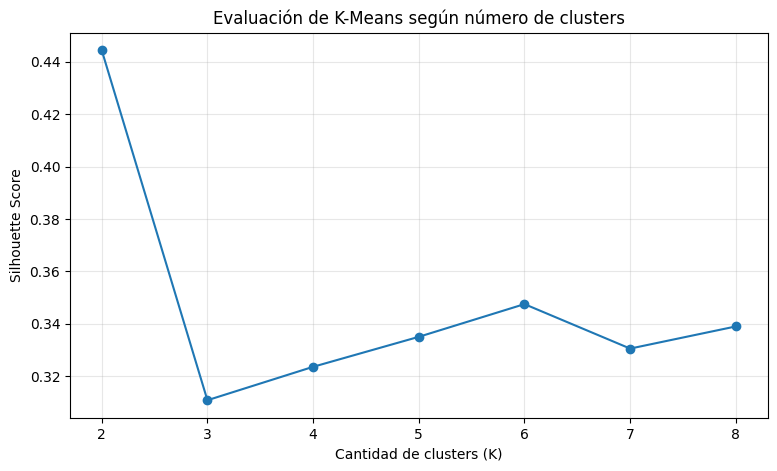

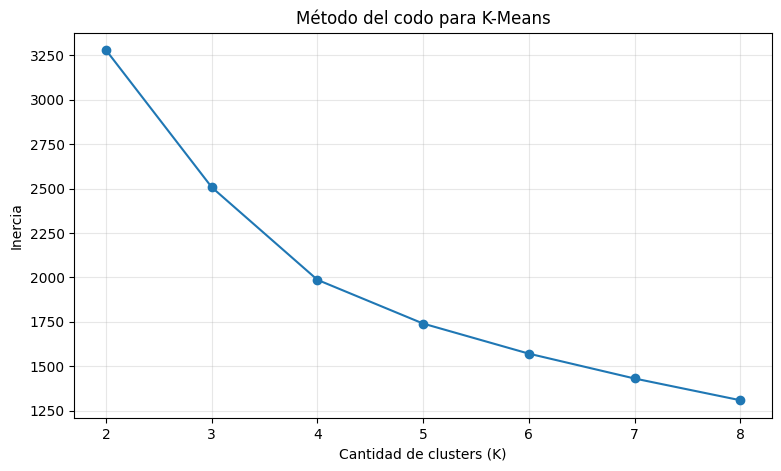

In [4]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Probar diferentes cantidades de clusters
resultados = []

for k in range(2, 9):

    modelo = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        random_state=42
    )

    etiquetas = modelo.fit_predict(X)

    score = silhouette_score(X, etiquetas)

    resultados.append({
        'Clusters': k,
        'Inercia': modelo.inertia_,
        'Silhouette': score
    })

# Mostrar resultados
resultados_df = pd.DataFrame(resultados)

print(resultados_df.round(4))

# Visualizar Silhouette
plt.figure(figsize=(9, 5))

plt.plot(
    resultados_df['Clusters'],
    resultados_df['Silhouette'],
    marker='o'
)

plt.title('Evaluación de K-Means según número de clusters')
plt.xlabel('Cantidad de clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)
plt.show()

# Visualizar método del codo
plt.figure(figsize=(9, 5))

plt.plot(
    resultados_df['Clusters'],
    resultados_df['Inercia'],
    marker='o'
)

plt.title('Método del codo para K-Means')
plt.xlabel('Cantidad de clusters (K)')
plt.ylabel('Inercia')
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)
plt.show()


In [5]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

# Combinaciones de parámetros
valores_eps = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2]
valores_min_samples = [5, 10, 15, 20, 25]

resultados = []

# Evaluar combinaciones
for eps in valores_eps:

    for min_samples in valores_min_samples:

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean'
        )

        etiquetas = modelo.fit_predict(X)

        # Identificar grupos y ruido
        grupos = set(etiquetas) - {-1}
        cantidad_clusters = len(grupos)

        ruido = sum(etiquetas == -1)
        porcentaje_ruido = (ruido / len(X)) * 100

        # Calcular Silhouette excluyendo ruido
        silhouette = None

        mask = etiquetas != -1

        if len(grupos) >= 2 and mask.sum() > len(grupos):

            silhouette = silhouette_score(
                X.loc[mask],
                etiquetas[mask]
            )

        resultados.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': cantidad_clusters,
            'ruido': ruido,
            'ruido_%': round(porcentaje_ruido, 2),
            'Silhouette': silhouette
        })

# Crear tabla de resultados
resultados_df = pd.DataFrame(resultados)

print("RESULTADOS DE OPTIMIZACIÓN DBSCAN")
print(resultados_df.to_string(index=False))

# Ordenar por Silhouette
print("\nMEJORES CONFIGURACIONES POR SILHOUETTE")

print(
    resultados_df
    .dropna(subset=['Silhouette'])
    .sort_values('Silhouette', ascending=False)
    .head(10)
    .to_string(index=False)
)


RESULTADOS DE OPTIMIZACIÓN DBSCAN
 eps  min_samples  clusters  ruido  ruido_%  Silhouette
 0.4            5        19    227    11.35    0.412691
 0.4           10        14    337    16.85    0.453222
 0.4           15        10    467    23.35    0.500731
 0.4           20        10    490    24.50    0.507292
 0.4           25         8    544    27.20    0.507592
 0.5            5        20    172     8.60    0.391699
 0.5           10        13    278    13.90    0.435454
 0.5           15        12    338    16.90    0.460309
 0.5           20        10    422    21.10    0.478547
 0.5           25         9    478    23.90    0.491263
 0.6            5        22    139     6.95    0.389039
 0.6           10        15    227    11.35    0.414068
 0.6           15        13    276    13.80    0.436279
 0.6           20        12    327    16.35    0.438809
 0.6           25         9    429    21.45    0.465997
 0.7            5        24     85     4.25    0.377819
 0.7          

In [6]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

eps_values = [0.90, 0.95, 1.00, 1.05, 1.10]
min_samples_values = [5, 8, 10, 12, 15]

resultados = []

for eps in eps_values:
    for min_samples in min_samples_values:

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean'
        )

        labels = modelo.fit_predict(X)

        conteos = pd.Series(labels).value_counts()
        grupos = conteos.drop(index=-1, errors='ignore')

        ruido = conteos.get(-1, 0)
        clusters = len(grupos)

        silhouette = None

        mask = labels != -1

        if clusters >= 2 and len(set(labels[mask])) >= 2:
            silhouette = silhouette_score(
                X.loc[mask],
                labels[mask]
            )

        resultados.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': clusters,
            'ruido': ruido,
            'ruido_%': round(ruido / len(X) * 100, 2),
            'grupo_minimo': grupos.min() if clusters else 0,
            'grupo_maximo': grupos.max() if clusters else 0,
            'silhouette': silhouette
        })

resultados_df = pd.DataFrame(resultados)

print(resultados_df.sort_values(
    'silhouette',
    ascending=False
).to_string(index=False))



 eps  min_samples  clusters  ruido  ruido_%  grupo_minimo  grupo_maximo  silhouette
1.00           12         2    127     6.35            27          1846    0.494718
1.00           10         3     99     4.95             9          1864    0.432185
0.90           15        14    188     9.40            15           562    0.404811
0.95           15        14    183     9.15            16           562    0.401706
0.90           12        15    162     8.10            16           562    0.399236
0.95           12        15    157     7.85            16           562    0.398066
0.90           10        17    135     6.75            10           562    0.390427
0.95           10        18    117     5.85            10           562    0.376111
0.90            8        22     79     3.95             8           562    0.371004
0.95            8        22     68     3.40             8           562    0.369440
0.90            5        22     46     2.30             9           562    0

In [7]:

from sklearn.cluster import DBSCAN

configuraciones = {
    'Configuracion_A': (1.0, 12),
    'Configuracion_B': (0.9, 15)
}

for nombre, parametros in configuraciones.items():

    eps, min_samples = parametros

    modelo = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric='euclidean'
    )

    etiquetas = modelo.fit_predict(X)

    df_resultado = df.copy()
    df_resultado['Cluster'] = etiquetas

    print("\n", nombre)
    print("eps:", eps)
    print("min_samples:", min_samples)

    print("\nCantidad de inmuebles por grupo:")
    print(df_resultado['Cluster'].value_counts().sort_index())

    print("\nCaracterísticas promedio:")
    print(
        df_resultado[df_resultado['Cluster'] != -1]
        .groupby('Cluster')[
            ['Habitaciones', 'Baños', 'Area', 'Valor']
        ]
        .mean()
        .round(2)
    )



 Configuracion_A
eps: 1.0
min_samples: 12

Cantidad de inmuebles por grupo:
Cluster
-1     127
 0    1846
 1      27
Name: count, dtype: int64

Características promedio:
         Habitaciones  Baños    Area         Valor
Cluster                                           
0                2.55   2.08   81.99  4.242151e+08
1                4.00   4.00  211.48  8.489259e+08

 Configuracion_B
eps: 0.9
min_samples: 15

Cantidad de inmuebles por grupo:
Cluster
-1     188
 0      92
 1     562
 2     255
 3      15
 4     141
 5     103
 6      82
 7      56
 8      16
 9     241
 10    121
 11     46
 12     54
 13     28
Name: count, dtype: int64

Características promedio:
         Habitaciones  Baños    Area         Valor
Cluster                                           
0                 1.0    1.0   43.46  3.183319e+08
1                 3.0    2.0   76.30  3.579491e+08
2                 2.0    2.0   72.96  4.320405e+08
3                 4.0    3.0  114.00  4.829533e+08
4               

In [8]:

# Reentrenar DBSCAN con configuración B

from sklearn.cluster import DBSCAN
import pandas as pd

modelo_dbscan = DBSCAN(
    eps=0.9,
    min_samples=15,
    metric='euclidean'
)

labels = modelo_dbscan.fit_predict(X)

# Incorporar resultados a la base original
df_analisis = df.copy()
df_analisis['Cluster'] = labels

# Excluir ruido para analizar los grupos
datos_grupos = df_analisis[
    df_analisis['Cluster'] != -1
]

# Perfil de cada grupo
perfil = datos_grupos.groupby('Cluster').agg(
    Cantidad=('Tipo', 'count'),
    Tipo_mas_frecuente=('Tipo',
                        lambda x: x.mode().iloc[0]),
    Habitaciones=('Habitaciones', 'mean'),
    Baños=('Baños', 'mean'),
    Area=('Area', 'mean'),
    Valor=('Valor', 'mean')
).round(2)

print("PERFIL DE LOS CLUSTERS")
print(perfil)

# Distribución por tipo de inmueble
print("\nDISTRIBUCIÓN DE TIPO POR CLUSTER")

print(pd.crosstab(
    df_analisis['Cluster'],
    df_analisis['Tipo']
))

# Barrios más frecuentes por cluster
print("\nBARRIOS MÁS FRECUENTES")

for cluster in sorted(datos_grupos['Cluster'].unique()):

    print(f"\nCluster {cluster}")

    print(
        datos_grupos[
            datos_grupos['Cluster'] == cluster
        ]['Barrio']
        .value_counts()
        .head(3)
    )


PERFIL DE LOS CLUSTERS
         Cantidad Tipo_mas_frecuente  Habitaciones  Baños    Area  \
Cluster                                                             
0              92        Apartamento           1.0    1.0   43.46   
1             562        Apartamento           3.0    2.0   76.30   
2             255        Apartamento           2.0    2.0   72.96   
3              15        Apartamento           4.0    3.0  114.00   
4             141        Apartamento           2.0    1.0   47.58   
5             103        Apartamento           1.0    2.0   55.10   
6              82        Apartamento           2.0    3.0   99.66   
7              56               Casa           3.0    3.0  121.82   
8              16               Casa           2.0    1.0   54.44   
9             241        Apartamento           3.0    3.0  119.69   
10            121        Apartamento           3.0    1.0   50.45   
11             46               Casa           3.0    2.0   93.39   
12         

Silhouette Score: 0.4571

Cantidad de inmuebles por cluster:
0    1479
1     521
Name: count, dtype: int64

Perfil de los clusters:
                       Habitaciones  Baños    Area         Valor
Cluster_KMeans_Prueba                                           
0                              2.46   1.81   66.84  3.276794e+08
1                              3.06   3.10  149.22  7.876572e+08


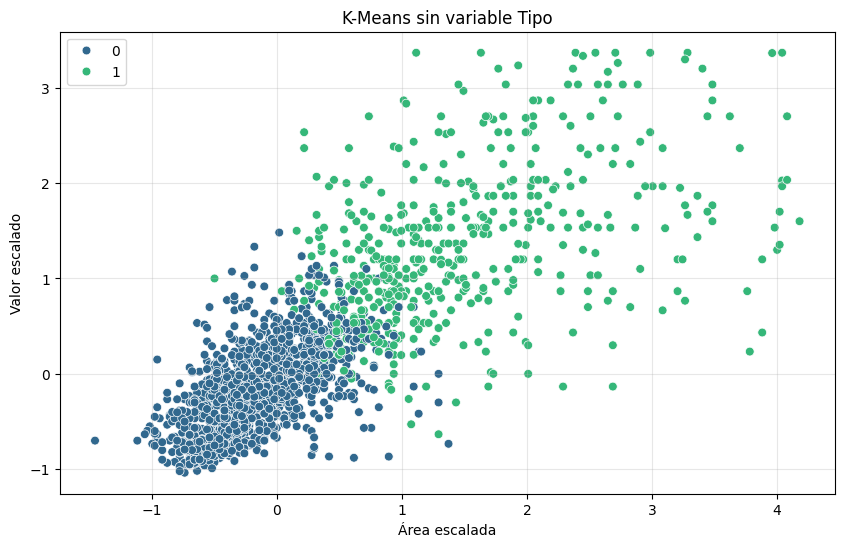

In [9]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar dataset
df = pd.read_csv('/content/Inmuebles_Bogota_2000_limpios.csv')

# 2. Seleccionar únicamente variables numéricas
variables = ['Habitaciones', 'Baños', 'Area', 'Valor']

# 3. Aplicar RobustScaler
scaler = RobustScaler()

X_prueba = pd.DataFrame(
    scaler.fit_transform(df[variables]),
    columns=variables
)

# 4. Entrenar K-Means con K=2
kmeans_prueba = KMeans(
    n_clusters=2,
    init='k-means++',
    n_init=20,
    random_state=42
)

labels = kmeans_prueba.fit_predict(X_prueba)

# 5. Evaluar modelo
print("Silhouette Score:",
      round(silhouette_score(X_prueba, labels), 4))

print("\nCantidad de inmuebles por cluster:")
print(pd.Series(labels).value_counts().sort_index())

# 6. Incorporar resultados
df['Cluster_KMeans_Prueba'] = labels

# 7. Características promedio
print("\nPerfil de los clusters:")
print(
    df.groupby('Cluster_KMeans_Prueba')[
        ['Habitaciones', 'Baños', 'Area', 'Valor']
    ].mean().round(2)
)

# 8. Visualizar agrupaciones
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_prueba['Area'],
    y=X_prueba['Valor'],
    hue=labels,
    palette='viridis',
    s=40
)

plt.title('K-Means sin variable Tipo')
plt.xlabel('Área escalada')
plt.ylabel('Valor escalado')
plt.grid(alpha=0.3)
plt.show()


Cantidad de inmuebles por cluster:
Cluster_DBSCAN
-1      81
 0      93
 1     609
 2     266
 3      29
 4     303
 5     157
 6     103
 7      86
 8     132
 9      70
 10     33
 11     38
Name: count, dtype: int64

Registros considerados ruido: 81
Porcentaje de ruido: 4.05 %

Silhouette Score: 0.3796

Características promedio:
                Habitaciones  Baños    Area         Valor
Cluster_DBSCAN                                           
0                        1.0    1.0   43.61  3.198552e+08
1                        3.0    2.0   77.79  3.561078e+08
2                        2.0    2.0   73.27  4.290351e+08
3                        4.0    3.0  121.86  4.493310e+08
4                        3.0    3.0  122.08  6.614495e+08
5                        2.0    1.0   48.28  1.838217e+08
6                        1.0    2.0   55.10  4.192261e+08
7                        2.0    3.0   98.55  6.322063e+08
8                        3.0    1.0   51.39  1.629515e+08
9                        3.0

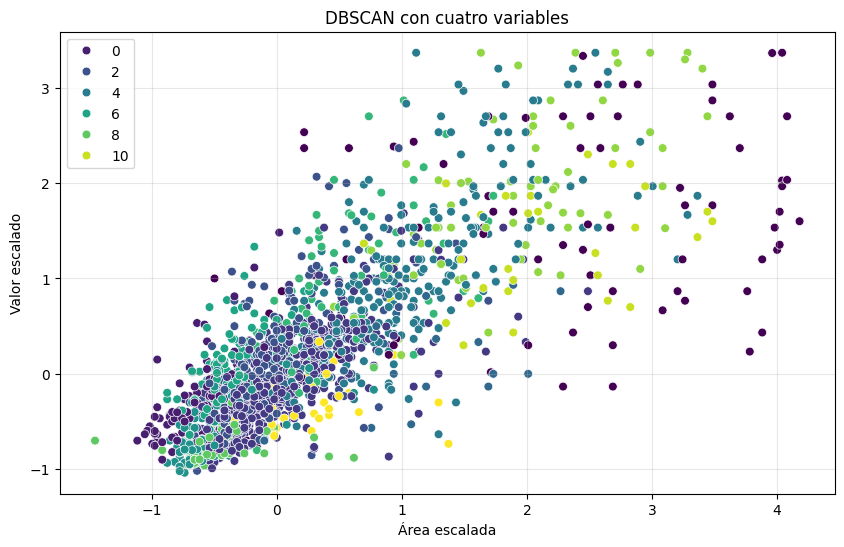

In [10]:

# ============================================
# DBSCAN CON 4 VARIABLES
# SIN INCLUIR TIPO
# ============================================

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar dataset
df = pd.read_csv('/content/Inmuebles_Bogota_2000_limpios.csv')

# 2. Seleccionar las mismas variables de K-Means
variables = [
    'Habitaciones',
    'Baños',
    'Area',
    'Valor'
]

# 3. Aplicar RobustScaler
scaler = RobustScaler()

X = pd.DataFrame(
    scaler.fit_transform(df[variables]),
    columns=variables
)

# 4. Entrenar DBSCAN
dbscan = DBSCAN(
    eps=0.9,
    min_samples=15,
    metric='euclidean'
)

labels = dbscan.fit_predict(X)

df['Cluster_DBSCAN'] = labels

# 5. Distribución de grupos
print("Cantidad de inmuebles por cluster:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

# 6. Identificar ruido
ruido = sum(labels == -1)

print("\nRegistros considerados ruido:", ruido)
print("Porcentaje de ruido:",
      round(ruido / len(df) * 100, 2), "%")

# 7. Evaluación
mask = labels != -1

clusters = set(labels[mask])

if len(clusters) >= 2:
    score = silhouette_score(
        X.loc[mask],
        labels[mask]
    )

    print("\nSilhouette Score:",
          round(score, 4))

# 8. Perfil de los grupos
print("\nCaracterísticas promedio:")

print(
    df[df['Cluster_DBSCAN'] != -1]
    .groupby('Cluster_DBSCAN')[
        variables
    ].mean().round(2)
)

# 9. Visualización
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X['Area'],
    y=X['Valor'],
    hue=labels,
    palette='viridis',
    s=40
)

plt.title('DBSCAN con cuatro variables')
plt.xlabel('Área escalada')
plt.ylabel('Valor escalado')
plt.grid(alpha=0.3)
plt.show()


In [11]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

# Variables definitivas
variables = ['Habitaciones', 'Baños', 'Area', 'Valor']

# Preparar matriz con RobustScaler
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X = pd.DataFrame(
    scaler.fit_transform(df[variables]),
    columns=variables
)

# Parámetros a evaluar
eps_values = [0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
min_samples_values = [10, 15, 20, 25]

resultados = []

# Evaluación de combinaciones
for eps in eps_values:

    for min_samples in min_samples_values:

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean'
        )

        labels = modelo.fit_predict(X)

        conteos = pd.Series(labels).value_counts()

        grupos = conteos.drop(
            index=-1,
            errors='ignore'
        )

        clusters = len(grupos)
        ruido = (labels == -1).sum()

        silhouette = None

        mask = labels != -1

        if clusters >= 2:

            silhouette = silhouette_score(
                X.loc[mask],
                labels[mask]
            )

        resultados.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': clusters,
            'ruido': ruido,
            'ruido_%': round(ruido / len(X) * 100, 2),
            'grupo_minimo': grupos.min() if clusters else 0,
            'grupo_maximo': grupos.max() if clusters else 0,
            'silhouette': silhouette
        })

# Tabla de resultados
resultados_df = pd.DataFrame(resultados)

print("RESULTADOS DE OPTIMIZACIÓN DBSCAN")
print(
    resultados_df.sort_values(
        'silhouette',
        ascending=False,
        na_position='last'
    ).to_string(index=False)
)


RESULTADOS DE OPTIMIZACIÓN DBSCAN
 eps  min_samples  clusters  ruido  ruido_%  grupo_minimo  grupo_maximo  silhouette
0.65           25         9    259    12.95            36           604    0.434105
0.65           20        10    207    10.35            37           604    0.415688
0.70           25        10    217    10.85            32           605    0.414298
0.75           25        10    192     9.60            37           607    0.407292
0.70           20        10    189     9.45            37           607    0.404252
0.80           25        10    175     8.75            38           608    0.403283
0.85           25        10    169     8.45            38           608    0.399588
0.80           20        10    163     8.15            38           608    0.398830
0.75           20        10    174     8.70            37           608    0.398742
0.65           15        11    160     8.00            20           606    0.396933
0.90           25        10    158     7.9

Dimensiones: (2000, 4)
Variables: ['Habitaciones', 'Baños', 'Area', 'Valor']

Distribución de clusters:
Cluster_DBSCAN
-1    259
 0     90
 1    604
 2    260
 3    154
 4    103
 5     76
 6    288
 7    130
 8     36
Name: count, dtype: int64

Registros de ruido: 259
Porcentaje de ruido: 12.95 %

Silhouette Score: 0.4341

Perfil de los clusters:
                Habitaciones  Baños    Area         Valor
Cluster_DBSCAN                                           
0                        1.0    1.0   42.31  3.069741e+08
1                        3.0    2.0   76.99  3.531120e+08
2                        2.0    2.0   72.18  4.177820e+08
3                        2.0    1.0   47.31  1.785066e+08
4                        1.0    2.0   55.10  4.192261e+08
5                        2.0    3.0   93.47  5.873354e+08
6                        3.0    3.0  117.99  6.347194e+08
7                        3.0    1.0   50.48  1.613349e+08
8                        4.0    2.0   85.67  3.028750e+08


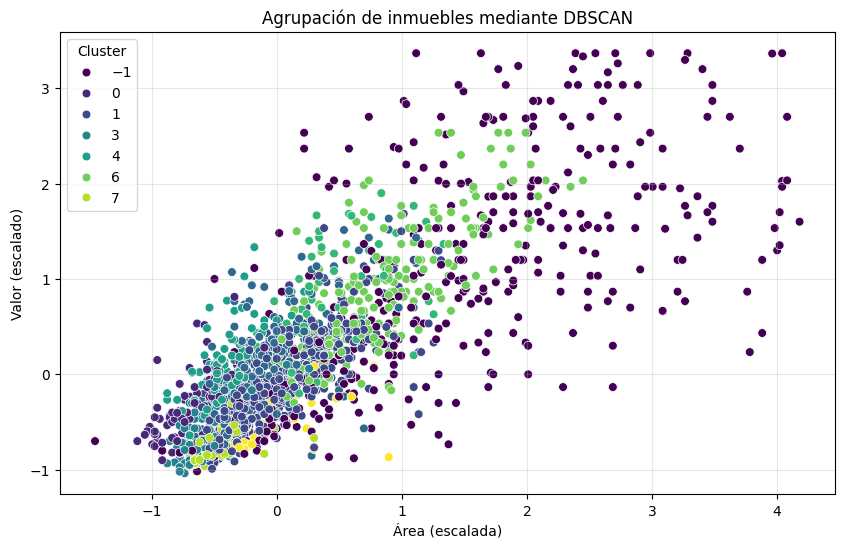

In [18]:
# Preparación definitiva de DBSCAN

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

df = pd.read_csv('/content/Inmuebles_Bogota_2000_limpios.csv')

# Las mismas cuatro variables utilizadas en K-Means
variables = ['Habitaciones', 'Baños', 'Area', 'Valor']

# Escalamiento
scaler = RobustScaler()

X = pd.DataFrame(
    scaler.fit_transform(df[variables]),
    columns=variables
)

# Verificar dimensiones
print("Dimensiones:", X.shape)
print("Variables:", X.columns.tolist())

# Ejecutar DBSCAN definitivo
modelo = DBSCAN(
    eps=0.65,
    min_samples=25,
    metric='euclidean'
)

labels = modelo.fit_predict(X)

# Distribución
df['Cluster_DBSCAN'] = labels

print("\nDistribución de clusters:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

# Ruido
ruido = sum(labels == -1)

print("\nRegistros de ruido:", ruido)
print("Porcentaje de ruido:", round(ruido / len(X) * 100, 2), "%")

# Silhouette
mask = labels != -1

if len(set(labels[mask])) >= 2:
    print("\nSilhouette Score:",
          round(silhouette_score(X.loc[mask], labels[mask]), 4))

# Perfil de agrupaciones
print("\nPerfil de los clusters:")
print(
    df[df['Cluster_DBSCAN'] != -1]
    .groupby('Cluster_DBSCAN')[variables]
    .mean()
    .round(2)
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X['Area'],
    y=X['Valor'],
    hue=labels_dbscan,
    palette='viridis',
    s=40
)

plt.title('Agrupación de inmuebles mediante DBSCAN')
plt.xlabel('Área (escalada)')
plt.ylabel('Valor (escalado)')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

### EVALUACIÓN DE ALGORITMOS

Dimensiones de la matriz: (2000, 4)

COMPARACIÓN DE MÉTRICAS
                       Metrica   K-Means   DBSCAN
              Silhouette Score    0.4571   0.4341
          Davies-Bouldin Index    0.9128   0.8865
       Calinski-Harabasz Index 1780.3300 721.0720
Tiempo de ejecución (segundos)    0.0356   0.0548

DISTRIBUCIÓN K-MEANS
0    1479
1     521
Name: count, dtype: int64

DISTRIBUCIÓN DBSCAN
-1    259
 0     90
 1    604
 2    260
 3    154
 4    103
 5     76
 6    288
 7    130
 8     36
Name: count, dtype: int64

REGISTROS CLASIFICADOS COMO RUIDO
Cantidad: 259
Porcentaje: 12.95 %


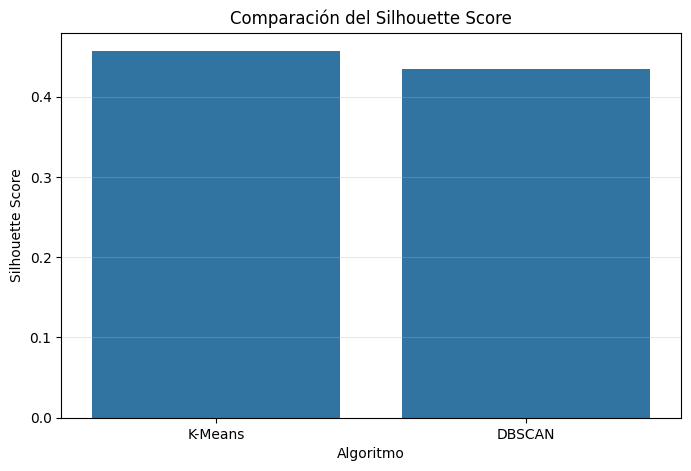

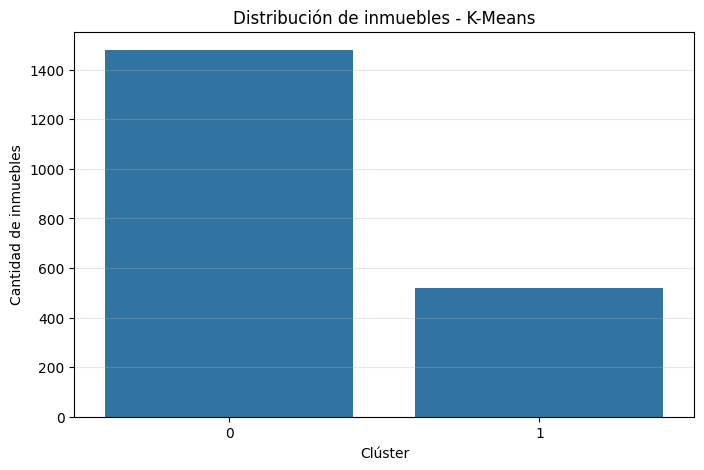

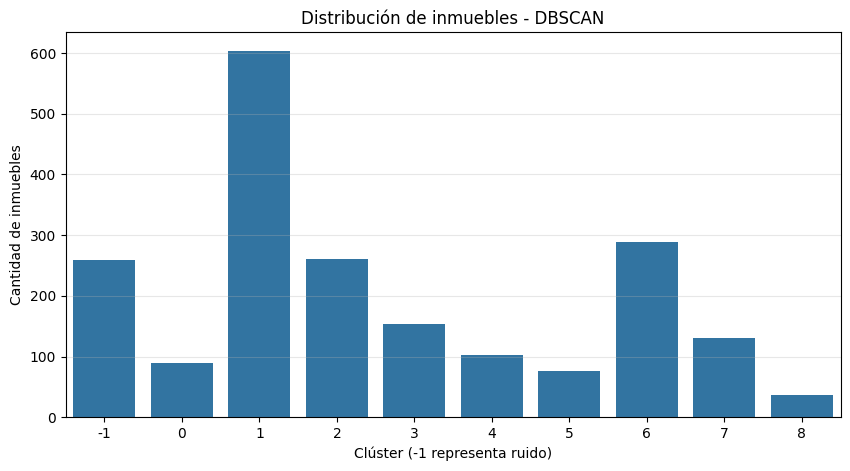

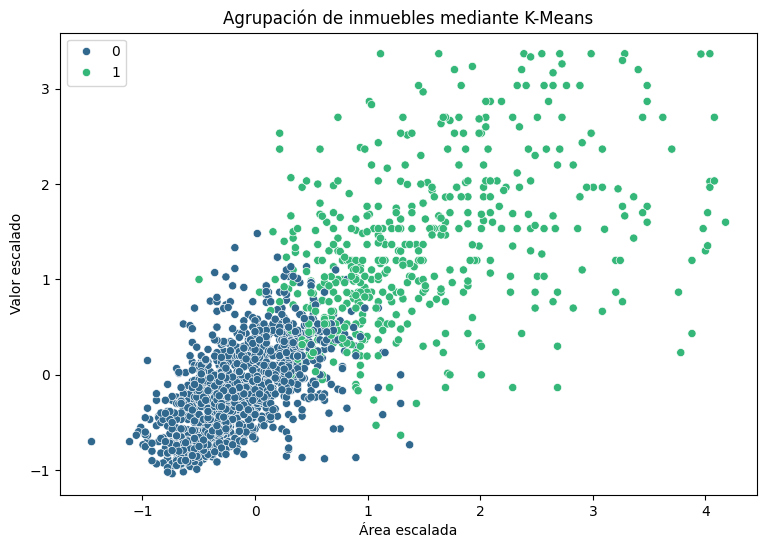

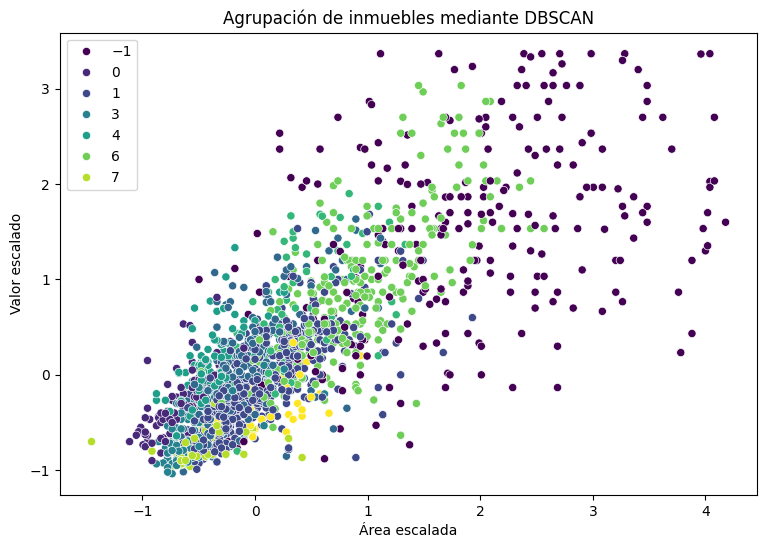


Evaluación final completada.


In [19]:

# ============================================
# FASE 6: EVALUACIÓN DE K-MEANS Y DBSCAN
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, DBSCAN

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# 1. CARGAR DATASET
df = pd.read_csv('/content/Inmuebles_Bogota_2000_limpios.csv')

# 2. SELECCIONAR LAS MISMAS VARIABLES
variables = ['Habitaciones', 'Baños', 'Area', 'Valor']

# 3. APLICAR ROBUST SCALER
scaler = RobustScaler()

X = pd.DataFrame(
    scaler.fit_transform(df[variables]),
    columns=variables
)

print("Dimensiones de la matriz:", X.shape)

# ============================================
# 4. ENTRENAR K-MEANS Y MEDIR TIEMPO
# ============================================

modelo_kmeans = KMeans(
    n_clusters=2,
    init='k-means++',
    n_init=20,
    random_state=42
)

inicio = time.perf_counter()

labels_kmeans = modelo_kmeans.fit_predict(X)

tiempo_kmeans = time.perf_counter() - inicio

# Calcular métricas K-Means
sil_kmeans = silhouette_score(X, labels_kmeans)

dbi_kmeans = davies_bouldin_score(X, labels_kmeans)

ch_kmeans = calinski_harabasz_score(X, labels_kmeans)

# ============================================
# 5. ENTRENAR DBSCAN Y MEDIR TIEMPO
# ============================================

modelo_dbscan = DBSCAN(
    eps=0.65,
    min_samples=25,
    metric='euclidean'
)

inicio = time.perf_counter()

labels_dbscan = modelo_dbscan.fit_predict(X)

tiempo_dbscan = time.perf_counter() - inicio

# Excluir registros identificados como ruido
mask = labels_dbscan != -1

X_dbscan = X.loc[mask]
labels_dbscan_validos = labels_dbscan[mask]

# Calcular métricas DBSCAN
sil_dbscan = silhouette_score(
    X_dbscan,
    labels_dbscan_validos
)

dbi_dbscan = davies_bouldin_score(
    X_dbscan,
    labels_dbscan_validos
)

ch_dbscan = calinski_harabasz_score(
    X_dbscan,
    labels_dbscan_validos
)

# ============================================
# 6. TABLA COMPARATIVA DE MÉTRICAS
# ============================================

comparacion = pd.DataFrame({
    'Metrica': [
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Index',
        'Tiempo de ejecución (segundos)'
    ],

    'K-Means': [
        sil_kmeans,
        dbi_kmeans,
        ch_kmeans,
        tiempo_kmeans
    ],

    'DBSCAN': [
        sil_dbscan,
        dbi_dbscan,
        ch_dbscan,
        tiempo_dbscan
    ]
})

print("\nCOMPARACIÓN DE MÉTRICAS")
print(comparacion.round(4).to_string(index=False))

# ============================================
# 7. DISTRIBUCIÓN DE LOS CLUSTERS
# ============================================

distribucion_kmeans = pd.Series(
    labels_kmeans
).value_counts().sort_index()

distribucion_dbscan = pd.Series(
    labels_dbscan
).value_counts().sort_index()

print("\nDISTRIBUCIÓN K-MEANS")
print(distribucion_kmeans)

print("\nDISTRIBUCIÓN DBSCAN")
print(distribucion_dbscan)

ruido = sum(labels_dbscan == -1)

print("\nREGISTROS CLASIFICADOS COMO RUIDO")
print("Cantidad:", ruido)
print("Porcentaje:", round(ruido / len(X) * 100, 2), "%")

# ============================================
# 8. GRÁFICA 1: COMPARACIÓN SILHOUETTE
# ============================================

plt.figure(figsize=(8, 5))

sns.barplot(
    x=['K-Means', 'DBSCAN'],
    y=[sil_kmeans, sil_dbscan]
)

plt.title('Comparación del Silhouette Score')
plt.ylabel('Silhouette Score')
plt.xlabel('Algoritmo')
plt.grid(axis='y', alpha=0.3)
plt.show()

# ============================================
# 9. GRÁFICA 2: DISTRIBUCIÓN K-MEANS
# ============================================

plt.figure(figsize=(8, 5))

sns.barplot(
    x=distribucion_kmeans.index.astype(str),
    y=distribucion_kmeans.values
)

plt.title('Distribución de inmuebles - K-Means')
plt.xlabel('Clúster')
plt.ylabel('Cantidad de inmuebles')
plt.grid(axis='y', alpha=0.3)
plt.show()

# ============================================
# 10. GRÁFICA 3: DISTRIBUCIÓN DBSCAN
# ============================================

plt.figure(figsize=(10, 5))

sns.barplot(
    x=distribucion_dbscan.index.astype(str),
    y=distribucion_dbscan.values
)

plt.title('Distribución de inmuebles - DBSCAN')
plt.xlabel('Clúster (-1 representa ruido)')
plt.ylabel('Cantidad de inmuebles')
plt.grid(axis='y', alpha=0.3)
plt.show()

# ============================================
# 11. GRÁFICA 4: AGRUPACIONES K-MEANS
# ============================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X['Area'],
    y=X['Valor'],
    hue=labels_kmeans,
    palette='viridis',
    s=35
)

plt.title('Agrupación de inmuebles mediante K-Means')
plt.xlabel('Área escalada')
plt.ylabel('Valor escalado')
plt.show()

# ============================================
# 12. GRÁFICA 5: AGRUPACIONES DBSCAN
# ============================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X['Area'],
    y=X['Valor'],
    hue=labels_dbscan,
    palette='viridis',
    s=35
)

plt.title('Agrupación de inmuebles mediante DBSCAN')
plt.xlabel('Área escalada')
plt.ylabel('Valor escalado')
plt.show()

# ============================================
# 13. EXPORTAR RESULTADOS
# ============================================

df['Cluster_KMeans'] = labels_kmeans
df['Cluster_DBSCAN'] = labels_dbscan

df.to_csv(
    '/content/Evaluacion_Final_Clustering.csv',
    index=False
)

print("\nEvaluación final completada.")
